In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os
os.chdir("/content/drive/MyDrive/simuteh-2330511067/notebook")
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511067/notebook


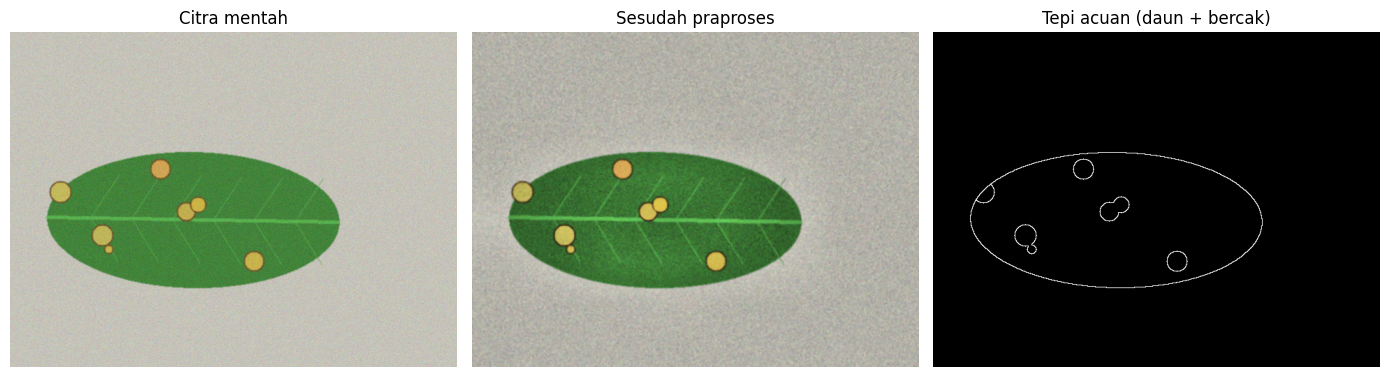

In [2]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json")) # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")
def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb
img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

In [3]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

Langkah 3.2 Citra biner awal

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.994                   192               5           0.551
1  teh_021.png          0.999                   167               1           0.017
2  teh_011.png          0.997                   216               0               -


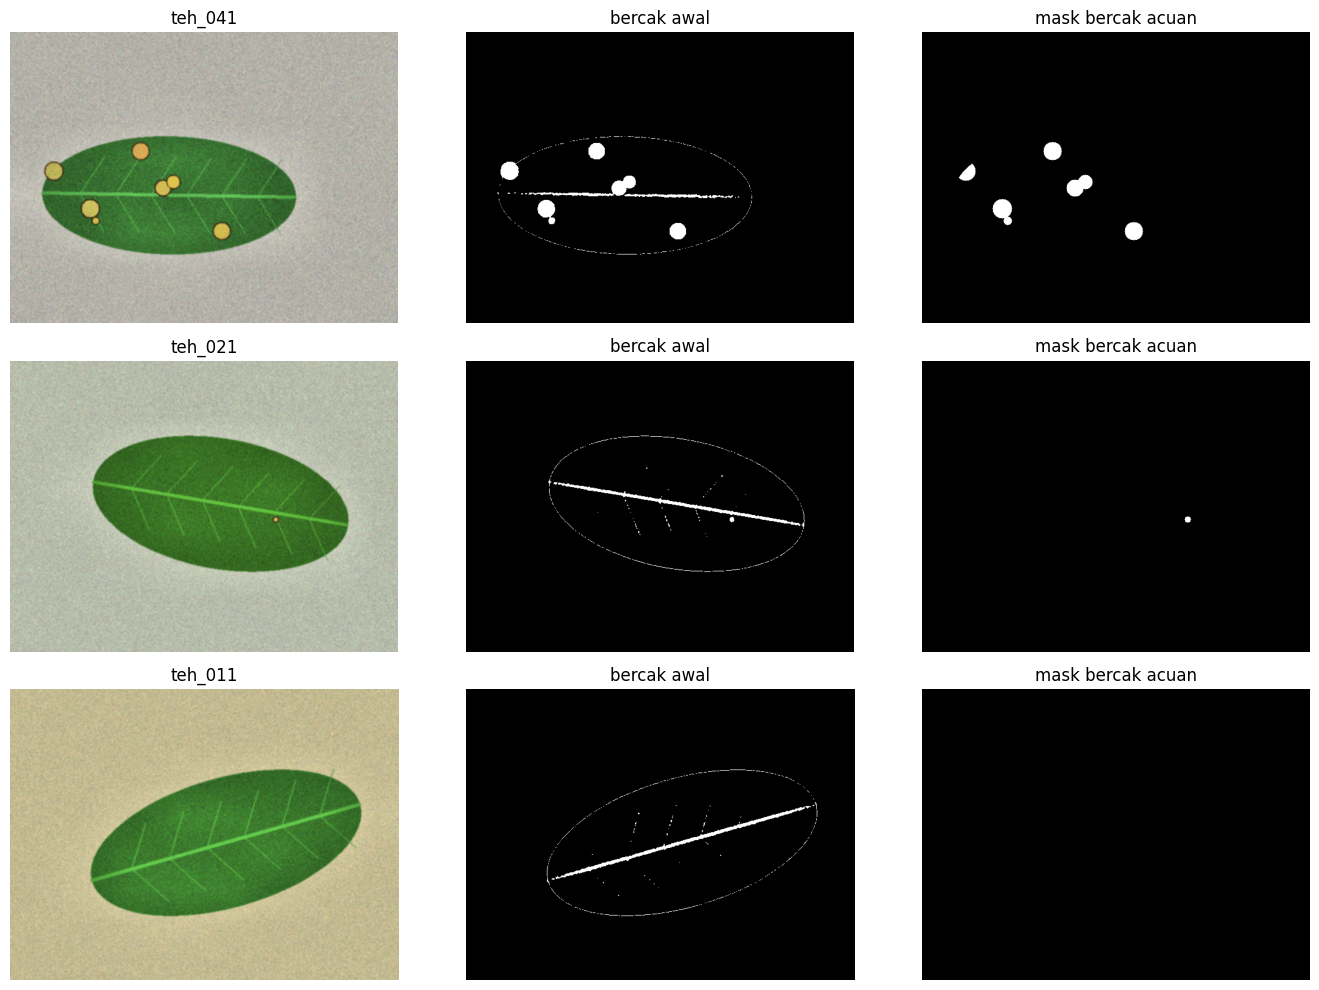

In [4]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:  # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))
plt.savefig("../hasil/p6_bercak_awal.png", dpi=150, bbox_inches="tight")

Langkah 3.3 Enam operasi

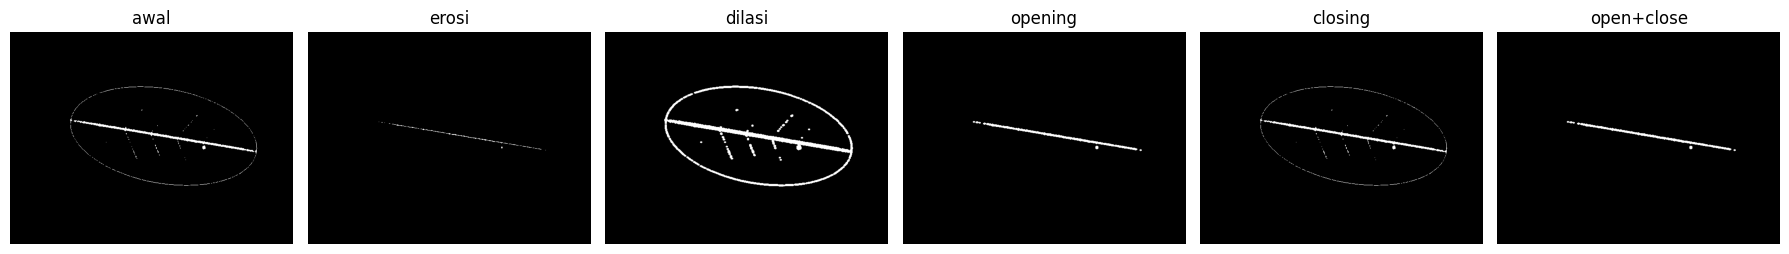

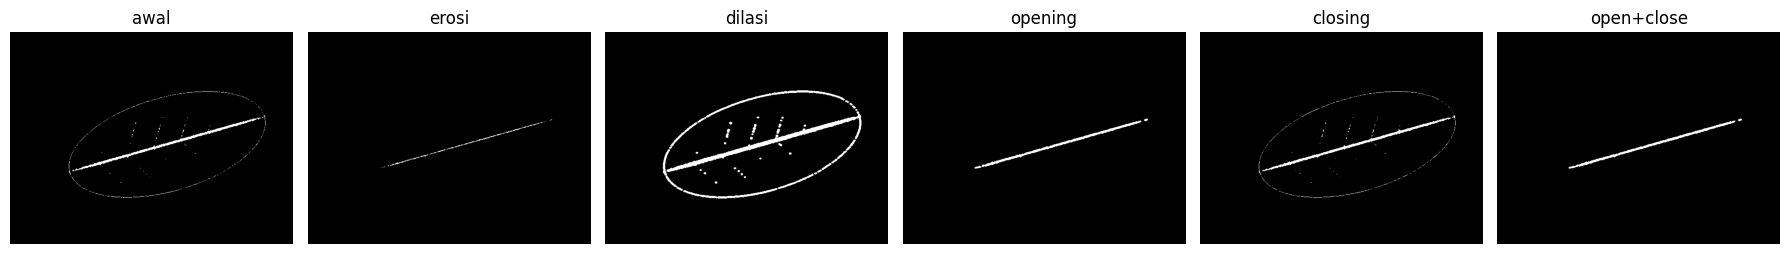

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       167    2950  0.017
1   teh_021.png       erosi        26     425  0.022
2   teh_021.png      dilasi        20    9516  0.009
3   teh_021.png     opening         5    1917  0.024
4   teh_021.png     closing       154    3005  0.017
5   teh_021.png  open+close         4    1919  0.024
6   teh_011.png        awal       216    3118      -
7   teh_011.png       erosi        16     613      -
8   teh_011.png      dilasi        33    9833      -
9   teh_011.png     opening         3    2142      -
10  teh_011.png     closing       196    3208      -
11  teh_011.png  open+close         2    2149      -


In [5]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.savefig(f"../hasil/3_3_{nama.replace('.png', '')}.png",
                dpi=300, bbox_inches="tight")
    plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

Langkah 3.4 Eksperimen ambang dan SE

In [6]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
                                     cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])

eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran",
                                   "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.55   0.12        14.20  19.75  20.20
          5       0.59   0.21         4.30   4.25   4.05
          7       0.69   0.39         2.30   1.70   2.65
  persegi 3       0.56   0.15         6.45   7.60   5.85
          5       0.64   0.29         3.35   3.15   3.65
          7       0.68   0.33         0.70   0.85   0.10
  silang  3       0.55   0.12        14.20  19.75  20.20
          5       0.60   0.20         7.15   8.45   6.85
          7       0.69   0.35         4.15   3.75   4.65
4 elips   3       0.62   0.24        11.75  15.00  11.40
          5       0.66   0.36         2.65   2.10   3.05
          7       0.69   0.41         0.70   0.95   0.85
  persegi 3       0.63   0.27         6.15   7.50   5.95
          5       0.68   0.37         1.85   1.40   1.75
          7       0.66   0.29  

Langkah 3.5 Gradien morfologi sebagai tepi daun

In [7]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))   # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])

print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
       .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.931     0.740
gelap                          0.990     0.706
kontras_rendah                 0.195     0.878
normal                         0.987     0.689
terang                         0.864     0.691


Langkah 3.6


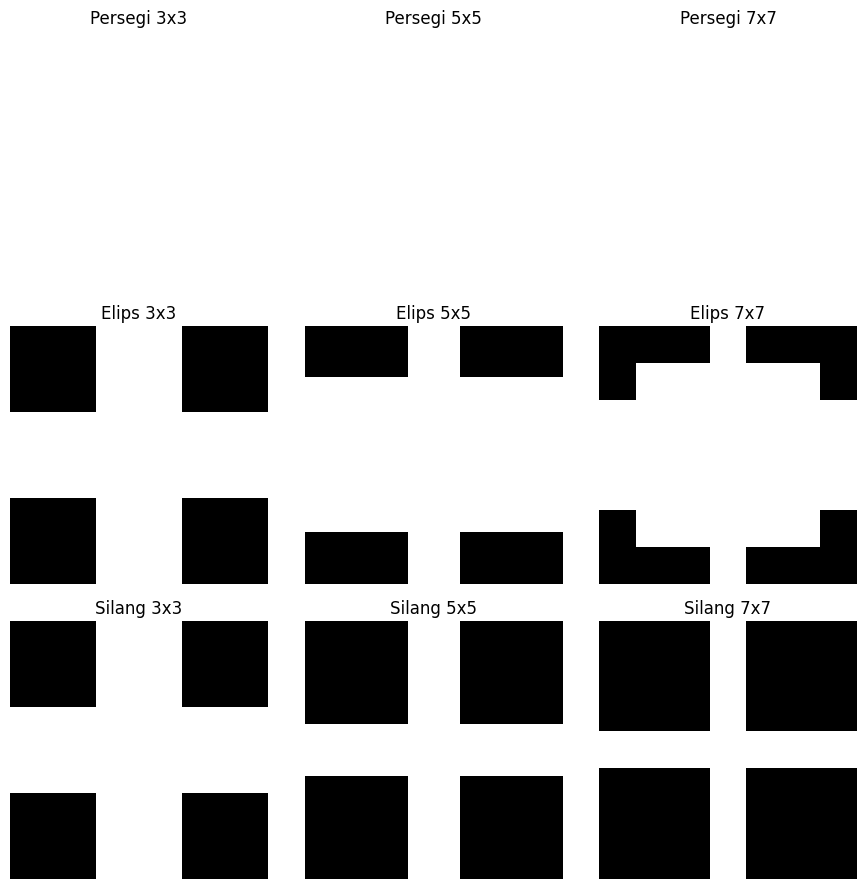

In [8]:
bentuk = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

ukuran = [3, 5, 7]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for i, (nama, bentuk_se) in enumerate(bentuk.items()):
    for j, k in enumerate(ukuran):
        se = cv2.getStructuringElement(bentuk_se, (k, k))

        axes[i, j].imshow(se, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(f"{nama} {k}x{k}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig("../hasil/3_6_panel_bentuk_SE.png",
            dpi=300, bbox_inches="tight")
plt.show()

Langkah 4.2 Label dan ukur

konektivitas 4: 11 komponen
konektivitas 8: 11 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      600    114.84         88.2       0.97         1.00  215  196
1       2      718    137.43         97.8       0.94         1.00   71  228
2       3      831    159.06        121.2       0.71         1.78  259  252
3       4       17      3.25         13.7       1.15         1.25  149  267
4       5      225     43.07        126.1       0.18        10.90  198  267
5       6       22      4.21         15.7       1.13         1.25  279  269
6       7       17      3.25         13.7       1.15         1.25  301  269
7       8      226     43.26        124.9       0.18        10.60  352  269
8       9       22      4.21         15.7       1.13         1.25  408  271
9      10      787    150.64        121.7       0.67         1.39  133  293
10     11      597    114.27         87.6       0.98         1.00  349  328


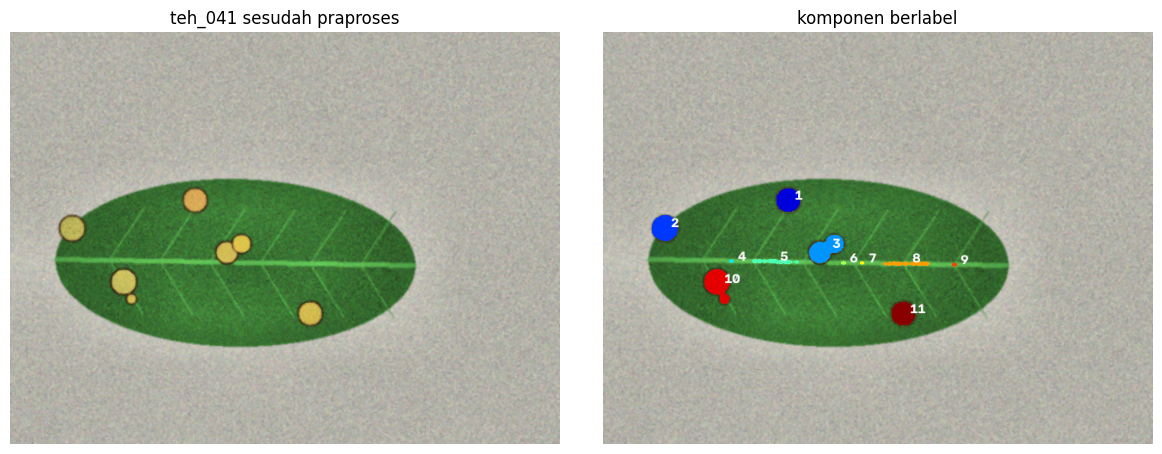

In [9]:
MM_PER_PX = 0.4375  # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)
warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
plt.savefig("../hasil/p6_komponen_teh041.png", dpi=150, bbox_inches="tight")  # panel untuk laporan

Langkah 4.3 Saring bercak palsu

In [10]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.50    0.95   0.90
luas + kebulatan + rasio   1.25    0.65   0.25
luas >= 20                 1.90    1.45   2.25
tanpa saring               2.65    2.10   3.05
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             7
luas + kebulatan + rasio     4
luas >= 20                  10
tanpa saring                11
Name: palsu, dtype: int64


Langkah 4.4 Kerjakan sendiri: dasar ambang penyaringan


(324, 7)
status
benar    177
palsu    147
Name: count, dtype: int64


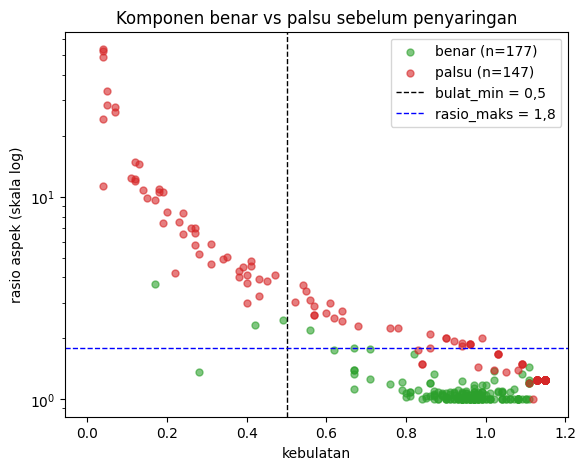

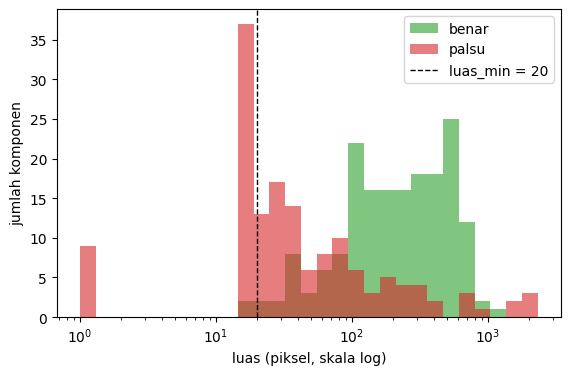

status               benar    palsu
luas_px     count   177.00   147.00
            mean    292.28   142.50
            std     226.66   356.63
            min      17.00     1.00
            25%     107.00    17.00
            50%     240.00    30.00
            75%     422.00    85.50
            max    1364.00  2332.00
kebulatan   count   177.00   147.00
            mean      0.93     0.70
            std       0.14     0.44
            min       0.17     0.00
            25%       0.90     0.27
            50%       0.95     0.84
            75%       1.00     1.14
            max       1.15     1.15
rasio_aspek count   177.00   147.00
            mean      1.12     4.93
            std       0.29     8.76
            min       1.00     0.00
            25%       1.00     1.25
            50%       1.04     1.75
            75%       1.09     4.40
            max       3.73    53.70
Palsu yang masih lolos ketiga aturan: 29
Benar yang terbuang oleh aturan   : 7
kelas
berat     14
ri

In [11]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    tabel_k, lbl = ukur_komponen(bersih)            # komponen sebelum disaring
    # samakan ukuran mask acuan dengan citra kerja (lebar 640), nearest agar tetap biner
    mb_r = cv2.resize(mb, (lbl.shape[1], lbl.shape[0]), interpolation=cv2.INTER_NEAREST)
    for _, r in tabel_k.iterrows():
        porsi = float((mb_r[lbl == r.label] > 0).mean())   # porsi piksel komponen di mask acuan
        status = "benar" if porsi > 0.5 else "palsu"
        baris.append([d.nama_file, d.kelas, r.luas_px, r.kebulatan, r.rasio_aspek, round(porsi, 3), status])

komp = pd.DataFrame(baris, columns=["nama", "kelas", "luas_px", "kebulatan", "rasio_aspek", "porsi", "status"])
komp.to_csv("../hasil/p6_komponen_benar_palsu.csv", index=False)
print(komp.shape)
print(komp.status.value_counts())

# --- Diagram 1: kebulatan vs rasio aspek ---
plt.figure(figsize=(6.5, 5))
for st, warna_ in [("benar", "tab:green"), ("palsu", "tab:red")]:
    sub = komp[komp.status == st]
    plt.scatter(sub.kebulatan, sub.rasio_aspek, c=warna_, alpha=0.6, s=25, label=f"{st} (n={len(sub)})")
plt.axvline(0.5, color="k", ls="--", lw=1, label="bulat_min = 0,5")
plt.axhline(1.8, color="b", ls="--", lw=1, label="rasio_maks = 1,8")
plt.yscale("log")
plt.xlabel("kebulatan"); plt.ylabel("rasio aspek (skala log)")
plt.title("Komponen benar vs palsu sebelum penyaringan")
plt.legend()
plt.savefig("../hasil/p6_sebar_benar_palsu.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Diagram 2: luas komponen, untuk menjustifikasi luas_min ---
plt.figure(figsize=(6.5, 4))
bins = np.logspace(np.log10(max(komp.luas_px.min(), 1)), np.log10(komp.luas_px.max()), 30)
for st, warna_ in [("benar", "tab:green"), ("palsu", "tab:red")]:
    plt.hist(komp[komp.status == st].luas_px, bins=bins, alpha=0.6, color=warna_, label=st)
plt.axvline(20, color="k", ls="--", lw=1, label="luas_min = 20")
plt.xscale("log")
plt.xlabel("luas (piksel, skala log)"); plt.ylabel("jumlah komponen"); plt.legend()
plt.savefig("../hasil/p6_hist_luas.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Angka pendukung untuk analisis ---
print(komp.groupby("status")[["luas_px", "kebulatan", "rasio_aspek"]].describe().T.round(2))

lolos = (komp.luas_px >= 20) & (komp.kebulatan >= 0.5) & (komp.rasio_aspek <= 1.8)
print("Palsu yang masih lolos ketiga aturan:", int(((komp.status == "palsu") & lolos).sum()))
print("Benar yang terbuang oleh aturan   :", int(((komp.status == "benar") & ~lolos).sum()))
print(komp[(komp.status == "palsu") & lolos].groupby("kelas").size())
print(komp[(komp.status == "benar") & ~lolos].sort_values("luas_px").head(10))

Langkah 5.2 Evaluasi menyeluruh

Galat absolut rerata persen bercak: 0.487
Korelasi persen prediksi vs acuan : 0.946
Akurasi kelas : 0.833
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             18              1      1
Bercak Ringan             0             13      7
Sehat                     0              1     19
kondisi
bayangan          1.00
gelap             0.75
kontras_rendah    0.83
normal            0.75
terang            0.83
Name: benar, dtype: float64


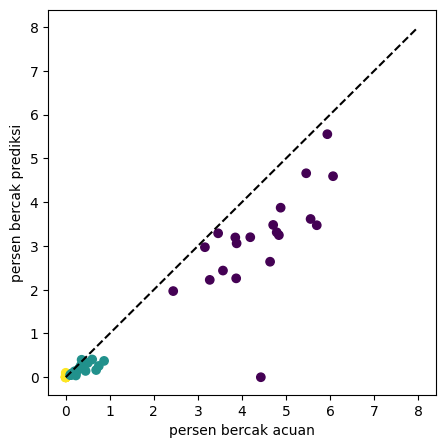

In [12]:
import importlib, bercak
importlib.reload(bercak)
PB = {}   # ubah parameter sesuai temuan Anda
bercak.simpan_param(PB)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))
plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.savefig("../hasil/p6_sebar_persen.png", dpi=150, bbox_inches="tight")   # tambahan: diagram sebar untuk laporan

In [13]:
import sys, os, importlib
src = os.path.abspath("../src")
if src not in sys.path:
    sys.path.insert(0, src)
importlib.invalidate_caches()
import bercak
print(bercak.__file__)

/content/drive/MyDrive/simuteh-2330511067/notebook/../src/bercak.py


Galat absolut rerata persen bercak: 0.487
Korelasi persen prediksi vs acuan : 0.946
Akurasi kelas : 0.833
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             18              1      1
Bercak Ringan             0             13      7
Sehat                     0              1     19
kondisi
bayangan          1.00
gelap             0.75
kontras_rendah    0.83
normal            0.75
terang            0.83
Name: benar, dtype: float64


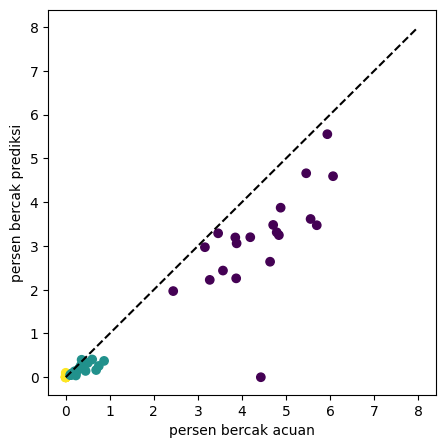

In [14]:
import importlib, bercak
importlib.reload(bercak)
PB = {}   # ubah parameter sesuai temuan Anda
bercak.simpan_param(PB)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))
plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.savefig("../hasil/p6_sebar_persen.png", dpi=150, bbox_inches="tight")   # tambahan: diagram sebar untuk laporan

Langkah 5.3 Kerjakan sendiri: analisis kesalahan.

10 citra salah kelas
          nama    kelas_acuan kelas_prediksi         kondisi  persen_acuan  persen_prediksi  jumlah_acuan  jumlah_prediksi
0  teh_012.png          Sehat  Bercak Ringan           gelap          0.00            0.101             0                2
1  teh_021.png  Bercak Ringan          Sehat          normal          0.11            0.065             1                1
2  teh_023.png  Bercak Ringan          Sehat          terang          0.23            0.082             2                2
3  teh_024.png  Bercak Ringan          Sehat  kontras_rendah          0.23            0.040             2                1
4  teh_027.png  Bercak Ringan          Sehat           gelap          0.12            0.049             1                1
5  teh_033.png  Bercak Ringan          Sehat          terang          0.10            0.048             1                1
6  teh_036.png  Bercak Ringan          Sehat          normal          0.15            0.087             1             

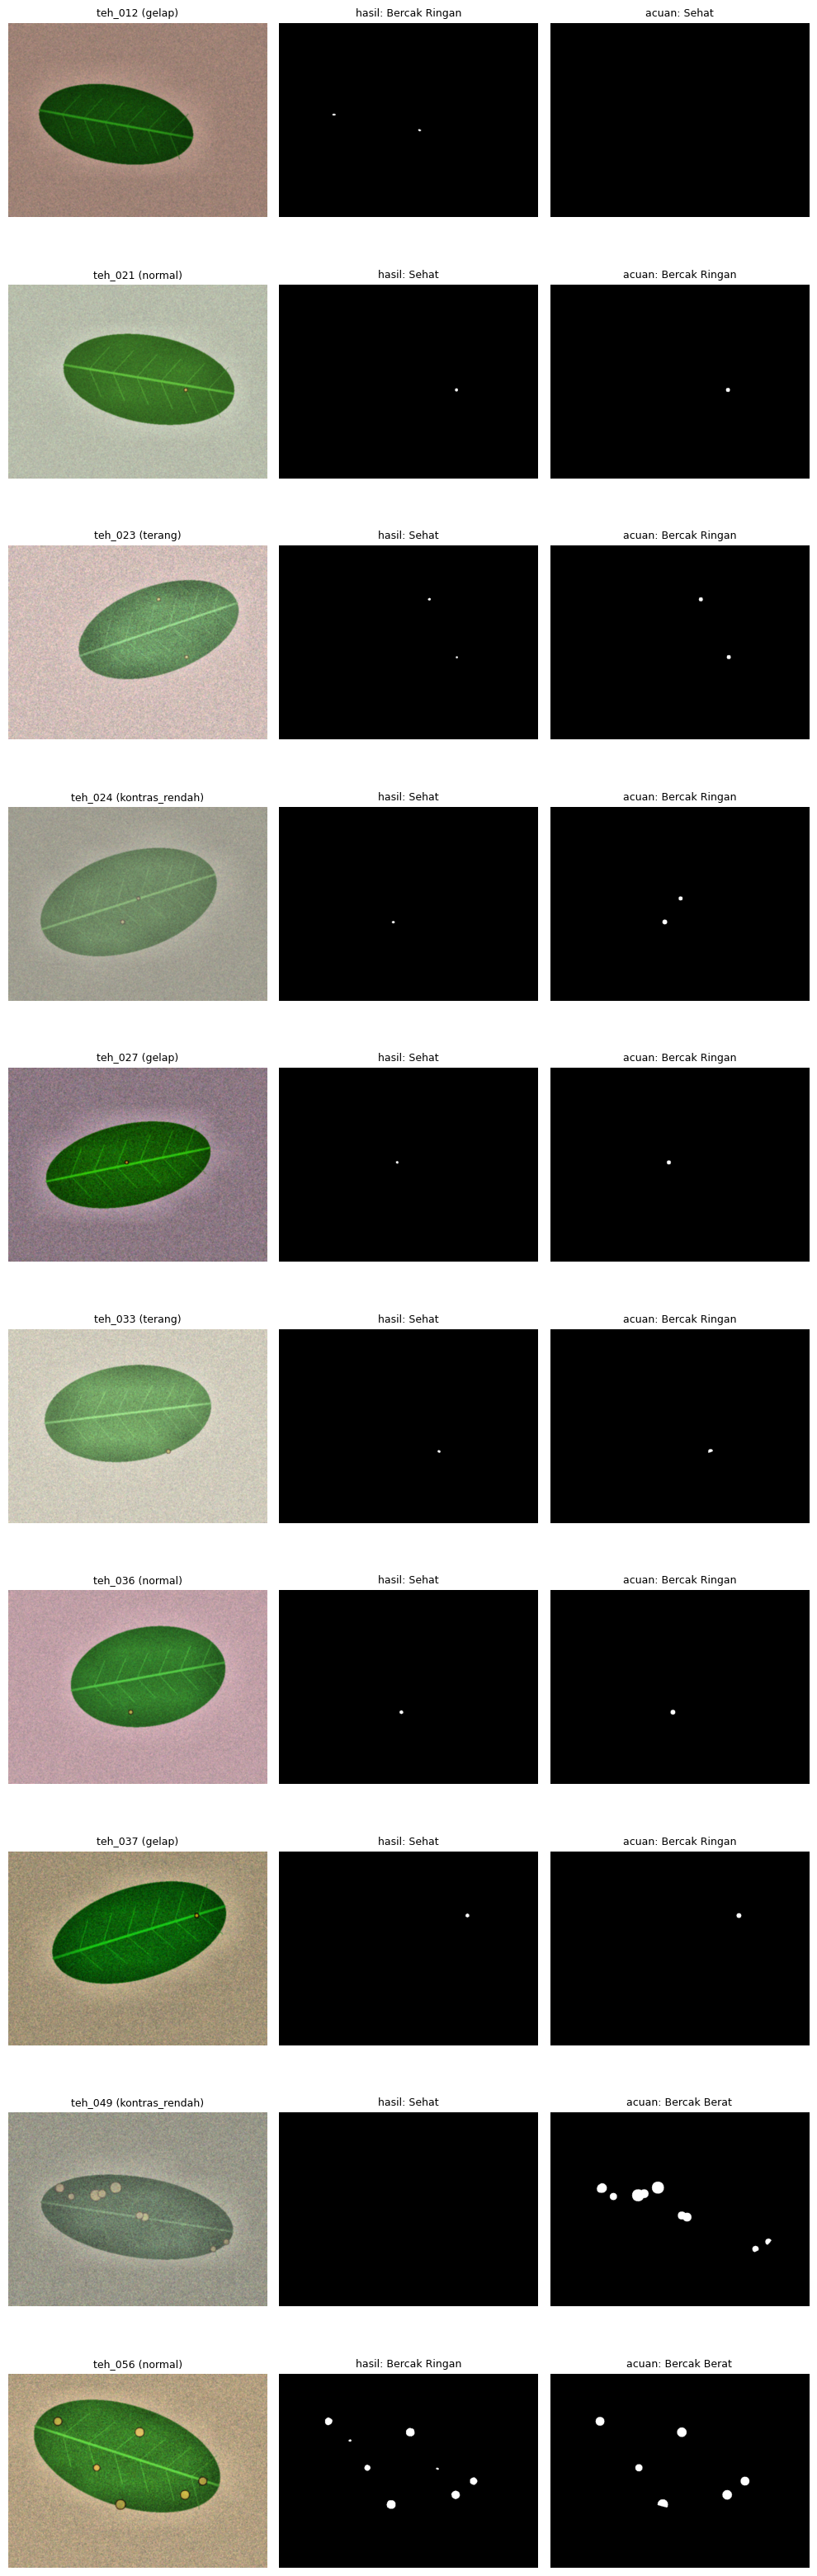

          nama         kondisi          acuan       prediksi  IoU_daun  %_acuan  %_awal  %_bersih  %_saring  n_acuan  n_awal  n_bersih  n_saring  IoU_bercak
0  teh_012.png           gelap          Sehat  Bercak Ringan     0.998    0.000   3.408     0.984     0.101        0     150        14         2       0.000
1  teh_021.png          normal  Bercak Ringan          Sehat     0.999    0.113   4.102     2.669     0.065        1     167         4         1       0.580
2  teh_023.png          terang  Bercak Ringan          Sehat     0.969    0.232   1.964     0.082     0.082        2     771         2         2       0.352
3  teh_024.png  kontras_rendah  Bercak Ringan          Sehat     0.987    0.228   1.326     0.040     0.040        2     277         1         1       0.175
4  teh_027.png           gelap  Bercak Ringan          Sehat     0.999    0.124   1.496     0.049     0.049        1     224         1         1       0.395
5  teh_033.png          terang  Bercak Ringan          Seh

In [15]:
p = {**bercak.PARAM_BERCAK, **PB}
salah = ev[ev.kelas_prediksi != ev.kelas_acuan].reset_index(drop=True)
print(len(salah), "citra salah kelas")
print(salah[["nama", "kelas_acuan", "kelas_prediksi", "kondisi", "persen_acuan",
             "persen_prediksi", "jumlah_acuan", "jumlah_prediksi"]])

diag = []
n = len(salah)
fig, ax = plt.subplots(n, 3, figsize=(10, 3.2 * n))
ax = np.atleast_2d(ax)
for i, d in salah.iterrows():
    img, md, mb = muat(d.nama)
    pra_ = praproses(img, PARAM)
    h = bercak.analisis_daun(pra_, PB)
    mb_r = cv2.resize(mb, (pra_.shape[1], pra_.shape[0]), interpolation=cv2.INTER_NEAREST)
    m_daun = h["mask_daun"]
    luas_daun = max(int((m_daun > 0).sum()), 1)
    b0 = bercak_awal(pra_, m_daun, kanal=p["kanal"], k=p["k"])   # biner awal
    b1 = bercak.bersihkan(b0, p)                                  # sesudah opening + closing
    b2 = h["mask_bercak"]                                         # sesudah penyaringan
    pers = lambda m: round(100 * int((m > 0).sum()) / luas_daun, 3)
    diag.append([d.nama, d.kondisi, d.kelas_acuan, d.kelas_prediksi,
                 round(iou(m_daun, md), 3),               # kualitas mask daun
                 pers(mb_r), pers(b0), pers(b1), pers(b2),  # persen per tahap
                 jumlah_komponen(mb_r), jumlah_komponen(b0), jumlah_komponen(b1), jumlah_komponen(b2),
                 round(iou(b2, mb_r), 3)])
    ax[i, 0].imshow(cv2.cvtColor(pra_, cv2.COLOR_BGR2RGB)); ax[i, 0].set_title(f"{d.nama[:7]} ({d.kondisi})", fontsize=9)
    ax[i, 1].imshow(b2, cmap="gray");  ax[i, 1].set_title(f"hasil: {d.kelas_prediksi}", fontsize=9)
    ax[i, 2].imshow(mb_r, cmap="gray"); ax[i, 2].set_title(f"acuan: {d.kelas_acuan}", fontsize=9)
    for a in ax[i]: a.axis("off")
plt.tight_layout()
plt.savefig("../hasil/p6_citra_salah_kelas.png", dpi=130, bbox_inches="tight")
plt.show()

kol = ["nama", "kondisi", "acuan", "prediksi", "IoU_daun", "%_acuan", "%_awal", "%_bersih", "%_saring",
       "n_acuan", "n_awal", "n_bersih", "n_saring", "IoU_bercak"]
diag = pd.DataFrame(diag, columns=kol)
print(diag)
diag.to_csv("../hasil/p6_diagnosis_salah.csv", index=False)